<a href="https://colab.research.google.com/github/PrinzVike/csc4110_G02/blob/main/G02_U8_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 – Group G2
## Task 8: Neural Networks
**Task owner:** Prince Emmanuel  
**Registration number:** COM/0072/23  
**Module:** 9

This notebook implements a perceptron, compares multilayer perceptron (MLP) classifiers, evaluates activation functions, and trains an MLP regressor.

**Input required:** `data/clean_insurance.csv` generated by your Task 2.2 notebook.  
**Important:** `bmi_smoker` is excluded from the smoker classifier because it is calculated using the target `smoker` and therefore leaks the answer.

In [ ]:
# Import the libraries needed for perceptrons, neural networks, preprocessing and evaluation.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, classification_report

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("outputs", exist_ok=True)

In [ ]:
# Load the transformed dataset produced by Task 2.2.
data_path = "sample_data/clean_insurance.csv"
if not os.path.exists(data_path):
    raise FileNotFoundError(
        "Missing data/clean_insurance.csv. Run Task 2.2 first and keep the file in data/."
    )

df_clean = pd.read_csv(data_path)
print("Dataset shape:", df_clean.shape)
display(df_clean.head())

Dataset shape: (1337, 13)


,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,log_charges,bmi_smoker,bmi_band
0,19,0,27.900,0,1,16884.92400,0,0,0,1,9.734176,27.9,25–30
1,18,1,33.770,1,0,1725.55230,0,0,1,0,7.453302,0.0,30 and over
2,28,1,33.000,3,0,4449.46200,0,0,1,0,8.400538,0.0,30 and over
3,33,1,22.705,0,0,21984.47061,0,1,0,0,9.998092,0.0,18.5–25
4,32,1,28.880,0,0,3866.85520,0,1,0,0,8.260197,0.0,25–30


## A. Perceptron by hand

A perceptron calculates a weighted sum of its inputs plus a bias, then applies a step activation. During training, its weights and bias are updated when its prediction differs from the target. The AND function is linearly separable, so a single perceptron can learn it. XOR is not linearly separable, so a single perceptron cannot represent its decision boundary.

In [ ]:
# Implement a single perceptron using a step activation and the perceptron update rule.
def step_activation(value):
    return 1 if value >= 0 else 0

def train_perceptron(X_data, y_data, learning_rate=0.1, epochs=30):
    weights = np.zeros(X_data.shape[1], dtype=float)
    bias = 0.0
    for _ in range(epochs):
        for inputs, target in zip(X_data, y_data):
            prediction = step_activation(np.dot(inputs, weights) + bias)
            error = target - prediction
            weights += learning_rate * error * inputs
            bias += learning_rate * error
    return weights, bias

def predict_perceptron(X_data, weights, bias):
    return np.array([
        step_activation(np.dot(row, weights) + bias) for row in X_data
    ])

# Train the perceptron on the two-input logical AND truth table.
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])

w_and, b_and = train_perceptron(X_and, y_and)
print("Final AND weights:", w_and)
print("Final AND bias:", b_and)
print("AND predictions:", predict_perceptron(X_and, w_and, b_and))
print("AND expected:    ", y_and)

Final AND weights: [0.2 0.1]
Final AND bias: -0.20000000000000004
AND predictions: [0 0 0 1]
AND expected:     [0 0 0 1]


In [ ]:
# Test the same single perceptron on XOR to demonstrate its limitation.
y_xor = np.array([0, 1, 1, 0])
w_xor, b_xor = train_perceptron(X_and, y_xor, epochs=100)
xor_predictions = predict_perceptron(X_and, w_xor, b_xor)
print("XOR predictions from one perceptron:", xor_predictions)
print("XOR expected:                       ", y_xor)
print("A single perceptron cannot correctly represent XOR because XOR is not linearly separable.")

XOR predictions from one perceptron: [1 1 0 0]
XOR expected:                        [0 1 1 0]
A single perceptron cannot correctly represent XOR because XOR is not linearly separable.


**Explanation:** A single perceptron creates one linear decision boundary. The two positive XOR cases lie on opposite corners of the input square, while the two negative cases occupy the other corners. No single straight line can separate these classes correctly. A multilayer network can combine multiple boundaries to represent XOR.

## B. Multi-layer perceptron for classification

The target is `smoker`. The model uses the prepared numeric features, excluding `smoker` itself and `bmi_smoker` (target leakage). The assignment's earlier classification task specifically examines how charges differ by smoking status, so `charges` is retained as a predictor here. The data is split with stratification so both sets preserve the smoker/non-smoker class proportions. Standardisation is fitted on the training partition only.

In [ ]:
# Prepare a leakage-conscious smoker classification dataset and make a stratified split.
classification_excluded = [
    "smoker", "bmi_smoker", "log_charges", "bmi_band"
]
X_clf = df_clean.drop(columns=classification_excluded, errors="ignore").copy()
y_clf = df_clean["smoker"].astype(int).copy()

X_clf = X_clf.apply(pd.to_numeric, errors="raise")
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

print("Training shape:", X_train_clf.shape)
print("Testing shape:", X_test_clf.shape)
print("Training class proportions:")
print(y_train_clf.value_counts(normalize=True))
print("Testing class proportions:")
print(y_test_clf.value_counts(normalize=True))

Training shape: (1069, 9)
Testing shape: (268, 9)
Training class proportions:
smoker
0    0.795136
1    0.204864
Name: proportion, dtype: float64
Testing class proportions:
smoker
0    0.794776
1    0.205224
Name: proportion, dtype: float64


In [ ]:
# Train the three required MLP architectures and store test accuracy and F1-score.
architectures = [(16,), (32, 16), (64, 32, 16)]
mlp_results_rows = []
trained_mlps = {}

for architecture in architectures:
    model = MLPClassifier(
        hidden_layer_sizes=architecture,
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=RANDOM_STATE,
        early_stopping=False
    )
    model.fit(X_train_clf_scaled, y_train_clf)
    predictions = model.predict(X_test_clf_scaled)
    trained_mlps[architecture] = model
    mlp_results_rows.append({
        "hidden_layers": str(architecture),
        "test_accuracy": accuracy_score(y_test_clf, predictions),
        "test_f1": f1_score(y_test_clf, predictions, zero_division=0),
        "iterations": model.n_iter_
    })

mlp_results = pd.DataFrame(mlp_results_rows).sort_values(
    "test_f1", ascending=False
).reset_index(drop=True)
display(mlp_results)

best_architecture = eval(mlp_results.loc[0, "hidden_layers"])
best_mlp = trained_mlps[best_architecture]
print("Best architecture by test F1:", best_architecture)

,hidden_layers,test_accuracy,test_f1,iterations
0,"(32, 16)",0.973881,0.935780,757
1,"(16,)",0.970149,0.925926,263
2,"(64, 32, 16)",0.958955,0.895238,321


Best architecture by test F1: (32, 16)


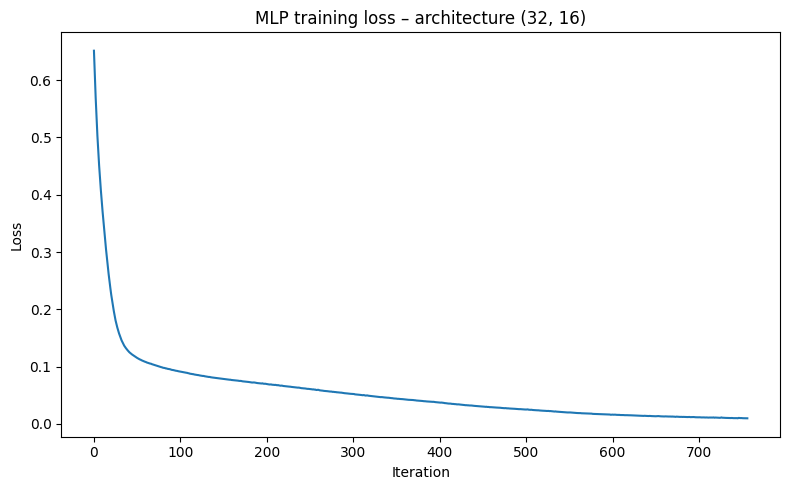

In [ ]:
# Plot and save the loss curve of the selected best neural network.
plt.figure(figsize=(8, 5))
plt.plot(best_mlp.loss_curve_)
plt.title(f"MLP training loss – architecture {best_architecture}")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig("outputs/loss_curve.png", dpi=300)
plt.show()

In [ ]:
# Evaluate the selected architecture with early stopping enabled.
early_mlp = MLPClassifier(
    hidden_layer_sizes=best_architecture,
    activation="relu",
    solver="adam",
    max_iter=2000,
    random_state=RANDOM_STATE,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20
)
early_mlp.fit(X_train_clf_scaled, y_train_clf)
early_predictions = early_mlp.predict(X_test_clf_scaled)

early_stopping_results = {
    "without_early_stopping_accuracy": accuracy_score(
        y_test_clf, best_mlp.predict(X_test_clf_scaled)
    ),
    "with_early_stopping_accuracy": accuracy_score(y_test_clf, early_predictions),
    "without_early_stopping_f1": f1_score(
        y_test_clf, best_mlp.predict(X_test_clf_scaled), zero_division=0
    ),
    "with_early_stopping_f1": f1_score(
        y_test_clf, early_predictions, zero_division=0
    ),
    "early_stopping_iterations": early_mlp.n_iter_
}
print(early_stopping_results)

{'without_early_stopping_accuracy': 0.9738805970149254, 'with_early_stopping_accuracy': 0.9477611940298507, 'without_early_stopping_f1': 0.9357798165137615, 'with_early_stopping_f1': 0.8653846153846154, 'early_stopping_iterations': 69}


## C. Exam skill: Compare activation functions

An activation function introduces non-linearity into a neural network, allowing it to learn relationships that a purely linear model cannot represent. This section trains the selected architecture with ReLU, tanh and logistic activations and records test accuracy and F1-score. In an MLP classifier, the output layer uses a probability-producing function appropriate for classification; the library handles this output layer automatically.

In [ ]:
# Train the best architecture with each required hidden-layer activation function.
activation_rows = []
activation_models = {}

for activation_name in ["relu", "tanh", "logistic"]:
    activation_model = MLPClassifier(
        hidden_layer_sizes=best_architecture,
        activation=activation_name,
        solver="adam",
        max_iter=2000,
        random_state=RANDOM_STATE,
        early_stopping=False
    )
    activation_model.fit(X_train_clf_scaled, y_train_clf)
    activation_predictions = activation_model.predict(X_test_clf_scaled)
    activation_models[activation_name] = activation_model
    activation_rows.append({
        "activation": activation_name,
        "test_accuracy": accuracy_score(y_test_clf, activation_predictions),
        "test_f1": f1_score(y_test_clf, activation_predictions, zero_division=0),
        "iterations": activation_model.n_iter_
    })

activation_results = pd.DataFrame(activation_rows).sort_values(
    "test_f1", ascending=False
).reset_index(drop=True)
display(activation_results)

,activation,test_accuracy,test_f1,iterations
0,logistic,0.985075,0.964912,209
1,relu,0.973881,0.935780,757
2,tanh,0.966418,0.915888,899


**Activation function interpretation:** ReLU returns zero for negative inputs and the input itself for positive inputs; it is often efficient to train. Tanh maps values to the range −1 to 1 and is zero-centred. Logistic (sigmoid) maps values to 0–1 and can be useful for probability-like hidden activations, although it may suffer from vanishing gradients. The output layer for binary classification should produce class probabilities (commonly sigmoid for one output, or softmax for two outputs); `MLPClassifier` manages this internally.

## D. Multi-layer perceptron for regression

The regression target is `charges`. The regression model uses the same prepared features as the charges-estimation task and excludes `charges`, `log_charges` and the EDA-only `bmi_band`. The split uses `random_state=42`; scaling is fitted only on the training data. The resulting test RMSE is stored as `mlp_reg_rmse`.

In [ ]:
# Prepare the regression features, split the data and scale using training data only.
regression_excluded = ["charges", "log_charges", "bmi_band"]
X_reg = df_clean.drop(columns=regression_excluded, errors="ignore").copy()
y_reg = df_clean["charges"].astype(float).copy()
X_reg = X_reg.apply(pd.to_numeric, errors="raise")

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Train the MLP regressor and calculate its test RMSE in the original dollar units.
mlp_reg = MLPRegressor(
    hidden_layer_sizes=best_architecture,
    activation="relu",
    solver="adam",
    max_iter=3000,
    early_stopping=True,
    random_state=RANDOM_STATE
)
mlp_reg.fit(X_train_reg_scaled, y_train_reg)
reg_predictions = mlp_reg.predict(X_test_reg_scaled)
mlp_reg_rmse = float(np.sqrt(mean_squared_error(y_test_reg, reg_predictions)))

print(f"MLP regression test RMSE: ${mlp_reg_rmse:,.2f}")

MLP regression test RMSE: $19,682.39


In [ ]:
# Compare the MLP regressor with a benchmark RMSE from Task 3.2 if it is available.
# Enter the best Task 3.2 test RMSE in dollars below after consulting Member 4's results.
best_task32_rmse = None  # Replace None with the actual numeric Task 3.2 RMSE.

if best_task32_rmse is None:
    print("Task 3.2 benchmark not entered. MLP test RMSE is:", round(mlp_reg_rmse, 2))
    print("Enter the actual best Task 3.2 test RMSE to complete the comparison.")
else:
    difference = mlp_reg_rmse - float(best_task32_rmse)
    if difference < 0:
        print(f"MLP improves on the Task 3.2 benchmark by ${abs(difference):,.2f} RMSE.")
    elif difference > 0:
        print(f"MLP RMSE is ${difference:,.2f} higher than the Task 3.2 benchmark.")
    else:
        print("MLP and the Task 3.2 benchmark have equal test RMSE.")

Task 3.2 benchmark not entered. MLP test RMSE is: 19682.39
Enter the actual best Task 3.2 test RMSE to complete the comparison.


## Written answers

Use the actual output values produced by running the notebook:

1. **Perceptron:** The perceptron learns the AND truth table because AND is linearly separable. It fails to learn XOR perfectly because XOR is not linearly separable and one linear decision boundary is insufficient.
2. **MLP architectures:** Compare the test accuracy and F1-score in `mlp_results`. The best network is selected by test F1 in this exercise; discuss both measures and note that a separate validation set or cross-validation is preferable for final model selection.
3. **Early stopping:** Compare the values in `early_stopping_results`. Early stopping monitors validation performance during training and stops when improvement stalls, which can reduce overfitting.
4. **Activation functions:** Compare ReLU, tanh and logistic using `activation_results`. Explain that activation functions introduce non-linearity and that the output layer uses a classification-appropriate probability function.
5. **Regression comparison:** Report `mlp_reg_rmse` and compare it with the actual best Task 3.2 test RMSE. Do not invent the Task 3.2 result.
6. **Neural network versus tree ensemble:** The assignment asks whether the neural network beat the best tree ensemble from Task 6. Obtain the actual Task 6 test result from the group and compare it with the neural-network result. A simpler model may still be preferable because it can be easier to interpret, faster to train and easier to maintain.

**Required graded evidence:** `w_and`, `b_and`, `mlp_results`, `best_mlp`, `activation_results`, `mlp_reg_rmse`, and `outputs/loss_curve.png`.